# Overlay a crop dataset on an environmental layer

Choose a crop and a static or TraCE layer. The layer is loaded over the crop file extent, which already includes the configured padding. Crop points are colored by time. Run the cells from top to bottom.

In [1]:
# Import plotting, array, and project data-loading tools.
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

# Add the project root so this notebook works when Jupyter starts in a subfolder.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'processing' / 'load_layers.py').exists():
    PROJECT_ROOT = next((parent for parent in Path.cwd().parents if (parent / 'processing' / 'load_layers.py').exists()), Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Import the same loaders used by the application.
from processing.load_layers import load_layer
from processing.load_data import load_data

In [2]:
# Choose one point dataset and one environmental layer to compare.
crop_name = 'wheat'
layer_name = 'prec'

# Use one degree-based resolution for every selected layer.
delta = 0.5

# Select the processed data folders used by the project.
CROP_DIRECTORY = PROJECT_ROOT / 'data' / 'processed' / 'crop'
LAYER_DIRECTORY = PROJECT_ROOT / 'data' / 'processed' / 'layers'

In [3]:
# Load crop observations and use the stored padded extents to select the layer window.
crop_data = load_data(crop_name, CROP_DIRECTORY)
year_extent = [crop_data['time'].min(), crop_data['time'].max()]  if layer_name in ['prec', 'temp' ] else None

latitude_extent = tuple(np.asarray(crop_data['lat_extent'], dtype=float))
longitude_extent = tuple(np.asarray(crop_data['lon_extent'], dtype=float))
layer_data = load_layer(
    layer_name,
    latitude_extent,
    longitude_extent,
    year_extent=year_extent,
    layer_directory=LAYER_DIRECTORY,
    delta=delta,
)

# Report the padded bounds and loaded shapes so mismatches are easy to spot.
print(f"Crop: {crop_name}; observations: {len(crop_data['lat']):,}")
print(f'Crop padded extent (degrees): latitude={latitude_extent}, longitude={longitude_extent}')
print(f"Layer: {layer_name}; grid shape={layer_data['data'].shape}")
print(f"Layer coordinate lengths: lat={len(layer_data['lat'])}, lon={len(layer_data['lon'])}")
if 'years' in layer_data:
    print(f"Layer years averaged: {layer_data['years'].min():g} to {layer_data['years'].max():g}")

Crop: wheat; observations: 908
Crop padded extent (degrees): latitude=(np.float64(7.2166999999999994), np.float64(64.35)), longitude=(np.float64(-14.82), np.float64(93.083905))
Layer: prec; grid shape=(115, 216)
Layer coordinate lengths: lat=115, lon=216
Layer years averaged: -10850 to -950.001


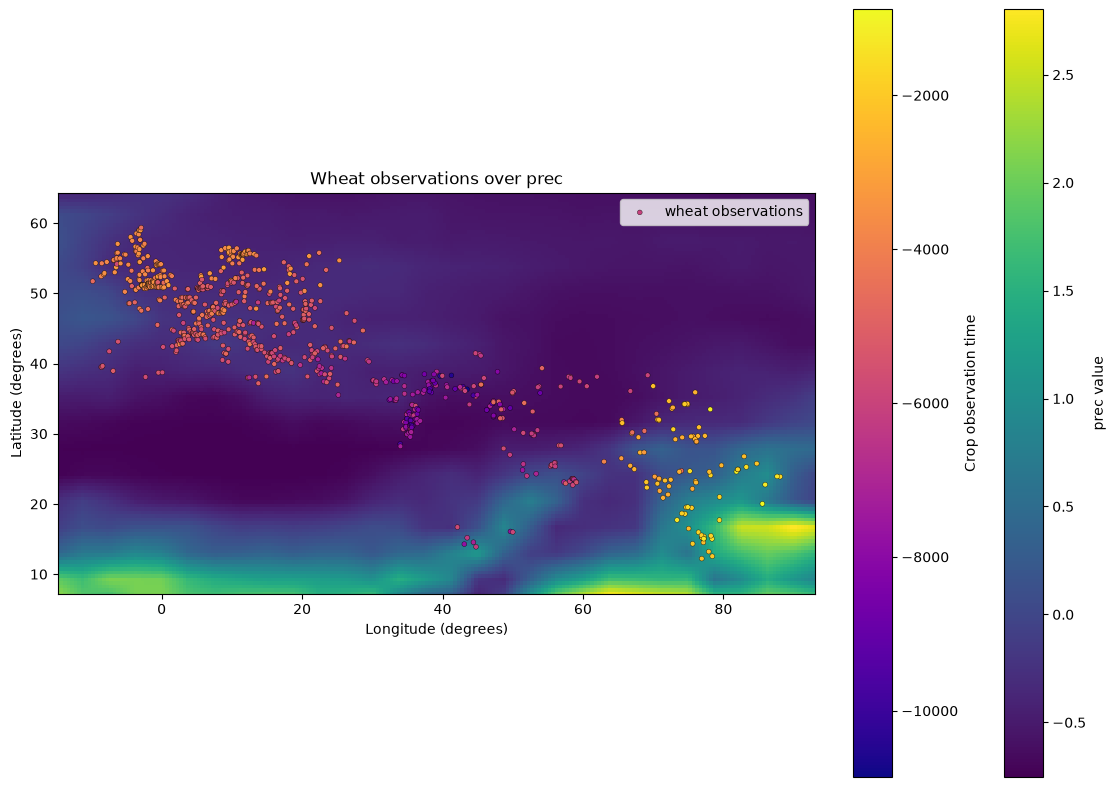

In [4]:
# Draw the environmental grid first, then overlay crop observations colored by their dates.
fig, ax = plt.subplots(figsize=(11, 8), constrained_layout=True)
mesh = ax.pcolormesh(
    layer_data['lon'],
    layer_data['lat'],
    np.ma.masked_invalid(layer_data['data']),
    shading='auto',
    cmap='viridis',
)
fig.colorbar(mesh, ax=ax, label=f'{layer_name} value')
points = ax.scatter(
    crop_data['lon'],
    crop_data['lat'],
    c=crop_data['time'],
    cmap='plasma',
    s=12,
    edgecolors='black',
    linewidths=0.25,
    label=f'{crop_name} observations',
)
fig.colorbar(points, ax=ax, label='Crop observation time')
ax.set_xlim(longitude_extent)
ax.set_ylim(latitude_extent)
ax.set_xlabel('Longitude (degrees)')
ax.set_ylabel('Latitude (degrees)')
ax.set_title(f'{crop_name.capitalize()} observations over {layer_name}')
ax.set_aspect('equal', adjustable='box')
ax.legend(loc='best')
plt.show()

In [5]:
import matplotlib.pyplot as plt

# Import the estimator to load the processed crop and geography layers.
from diffusion_estimator import DiffusionEstimator

# Define a small, reproducible single-theta example for manual inspection.
crop_name = "wheat"
layer_names = ["prec", "sea"]
theta = np.array([-2.,  0.,  5.], dtype=float)
repetitions = 100
estimator = DiffusionEstimator(crop_name, layer_names)
speed = estimator.build_speed(theta)

# Calculate the averaged Monte Carlo field and the observed-data error.
arrival_times, mean_squared_error = estimator.calculate_simulation_times_and_error(
    speed,
    n_reps=repetitions,
    random_state=3,
)
print(f"Crop: {crop_name}")
print(f"Layers: {', '.join(layer_names)}")
print(f"Theta: {theta}")
print(f"Monte Carlo repetitions: {repetitions}")
print(f"Mean squared error: {mean_squared_error:.6f}")

Crop: wheat
Layers: prec, sea
Theta: [-2.  0.  5.]
Monte Carlo repetitions: 100
Mean squared error: 1645153.788722


In [6]:
np.sqrt(mean_squared_error)

np.float64(1282.6354855228615)

## Wheat MATLAB and Python Monte Carlo comparison

The saved table was computed on 28 October 2026. It uses each wheat fit's full-precision theta, repetition count, and `result.squared_error` from MATLAB's `filename_database.mat`; displayed theta values are rounded. MSE is in years squared. Python runs at `delta=0.5`, `dt=40`, and `apply_w=True`, with seed 12 for repeatability. The random streams still differ. The extra Python column scores the same arrival field against MATLAB's saved observation bins; the `asym` fit cannot be reproduced by the Python speed model. Rerun the cell to refresh the table; the HydroSHEDS row may take several minutes to load.


In [9]:
# Read the MATLAB fit database and compare supported wheat models at stored theta and n.
from pathlib import Path
from scipy.io import loadmat
from IPython.display import Markdown, display
from calculate_errors import calculate_mse
from diffusion_estimator import DiffusionEstimator
import numpy as np

database_path = PROJECT_ROOT.parent / 'bottlenecks' / 'generated_data' / 'sweep_grad_descent' / 'filename_database.mat'
database = loadmat(database_path, simplify_cells=True, variable_names=['database'])['database']
wheat_entries = [entry for entry in database if entry['dataset'] == 'wheat']
comparison_rows = []

for entry in wheat_entries:
    # Resolve the file from the database, with a local-name fallback if it moved.
    layers = [str(layer) for layer in np.atleast_1d(entry['layers']) if str(layer) != 'av']
    fit_path = Path(entry['file'])
    if not fit_path.exists():
        fit_path = database_path.parent / fit_path.name
    fit = loadmat(
        fit_path,
        simplify_cells=True,
        variable_names=['theta_optim', 'number_of_averages', 'parameters', 'result'],
    )
    theta = np.atleast_1d(fit['theta_optim']).astype(float)
    n_averages = int(fit['number_of_averages'])
    matlab_mse = float(fit['result']['squared_error'])
    if not np.allclose(theta, np.atleast_1d(entry['theta']).astype(float)):
        raise ValueError(f'Database theta differs from {fit_path.name}')
    if not np.isclose(matlab_mse, float(entry['best_error'])):
        raise ValueError(f'Database error differs from {fit_path.name}')

    # A directional asym coefficient has no matching Python speed term.
    row = {'layers': ', '.join(layers) if layers else 'av', 'theta': theta,
           'n': n_averages, 'matlab_mse': matlab_mse, 'file': fit_path.name}
    if 'asym' in layers:
        row['status'] = 'unsupported asym term'
        comparison_rows.append(row)
        continue

    # Match the MATLAB 0.5-degree grid and check its saved observation cells.
    estimator = DiffusionEstimator('wheat', layers, delta=0.5, dt=40)
    matlab_data = np.asarray(fit['parameters']['dataset_idx'], dtype=float).copy() - 1.0
    if estimator.dataset.shape != matlab_data.shape or not np.array_equal(
        estimator.dataset[:, :2], matlab_data[:, :2]
    ):
        raise ValueError(f'Observation locations differ for {fit_path.name}')
    if estimator.grid_shape != fit['parameters']['W'].shape:
        raise ValueError(f'Model grids differ for {fit_path.name}')

    # Simulate once, then score the arrival field against each observation-time convention.
    speed = estimator.build_speed(theta)
    arrival, app_mse = estimator.calculate_simulation_times_and_error(
        speed, n_reps=n_averages, random_state=12, apply_w=True
    )
    row['python_app_mse'] = float(app_mse)
    row['python_matlab_bins_mse'] = float(calculate_mse(matlab_data, arrival, estimator.dt))
    row['time_bin_mismatches'] = int(np.count_nonzero(estimator.dataset[:, 2] != matlab_data[:, 2]))
    row['weight_max_abs_diff'] = float(np.max(np.abs(
        fit['parameters']['W'] - np.cos(np.deg2rad(estimator.latitude))[:, None]
    )))
    row['status'] = 'compared'
    comparison_rows.append(row)

# Format only the displayed numbers; every simulation used full stored theta precision.
table = ['| Layers | Theta | Averages | MATLAB MSE | Python MSE | Python MSE on MATLAB bins | Difference |',
         '| --- | --- | ---: | ---: | ---: | ---: | ---: |']
for row in comparison_rows:
    theta_text = ', '.join(f'{value:.4f}' for value in row['theta'])
    if row['status'] == 'compared':
        difference = 100 * (row['python_app_mse'] / row['matlab_mse'] - 1)
        table.append(f"| {row['layers']} | {theta_text} | {row['n']} | {row['matlab_mse']:,.1f} | "
                     f"{row['python_app_mse']:,.1f} | {row['python_matlab_bins_mse']:,.1f} | {difference:+.2f}% |")
    else:
        table.append(f"| {row['layers']} | {theta_text} | {row['n']} | {row['matlab_mse']:,.1f} | "
                     f"{row['status']} | - | - |")
display(Markdown('\n'.join(table)))

# Report the two checks that affect how directly the MSE columns can be compared.
compared = [row for row in comparison_rows if row['status'] == 'compared']
print(f"Observation time-bin mismatches: {compared[0]['time_bin_mismatches']} of "
      f"{estimator.dataset.shape[0]} wheat records")
print(f"Maximum absolute MATLAB/Python W difference: "
      f"{max(row['weight_max_abs_diff'] for row in compared):.3g}")


| Layers | Theta | Averages | MATLAB MSE | Python MSE | Python MSE on MATLAB bins | Difference |
| --- | --- | ---: | ---: | ---: | ---: | ---: |
| av | -1.2149 | 100 | 2,524,492.3 | 2,532,735.8 | 2,531,627.1 | +0.33% |
| asym, sea | -1.9342, 0.1551, 2.8552 | 100 | 1,588,206.2 | unsupported directional asym term | - | - |
| csi, sea | -2.0163, 0.1289, 2.8333 | 100 | 1,590,117.6 | 1,594,937.8 | 1,594,596.6 | +0.30% |
| hydro, sea | -1.8570, -0.8867, 2.5084 | 100 | 1,591,569.1 | 3,683,472.7 | 3,683,186.5 | +131.44% |
| prec, sea | -0.2918, 3.7969, 3.2552 | 100 | 1,418,307.1 | 1,733,708.0 | 1,734,984.8 | +22.24% |
| tmean, sea | -1.3664, -1.0623, 2.9682 | 100 | 1,481,976.0 | 1,537,896.5 | 1,537,329.3 | +3.77% |
| sea | -1.8716, 2.3778 | 100 | 1,667,256.8 | 1,668,891.4 | 1,668,495.6 | +0.10% |


Observation time-bin mismatches: 18 of 908 wheat records
Maximum absolute MATLAB/Python W difference: 1.67e-16


## Wheat hydro and sea: saved MATLAB layers versus app layers

The MATLAB fit stores hydro and sea in `parameters.X[0]` and `[1]`. This section compares those arrays with the app's processed layers on the same 0.5° wheat grid. The final cell reruns the Python solver with the MATLAB layers to isolate the input difference.

Grid: (115, 216); sea mismatches: 0/24840
Hydro: MAE=0.206600; RMSE=0.898134; max |difference|=20.030518
Hydro correlation: same cell=0.610465; Python shifted north one row=0.994135
Maximum hydro cell: MATLAB=(48, 91), Python=(47, 91)
EU tile top: native 61.995833°, MATLAB placement 62.25°, global-resize centre 61.75°


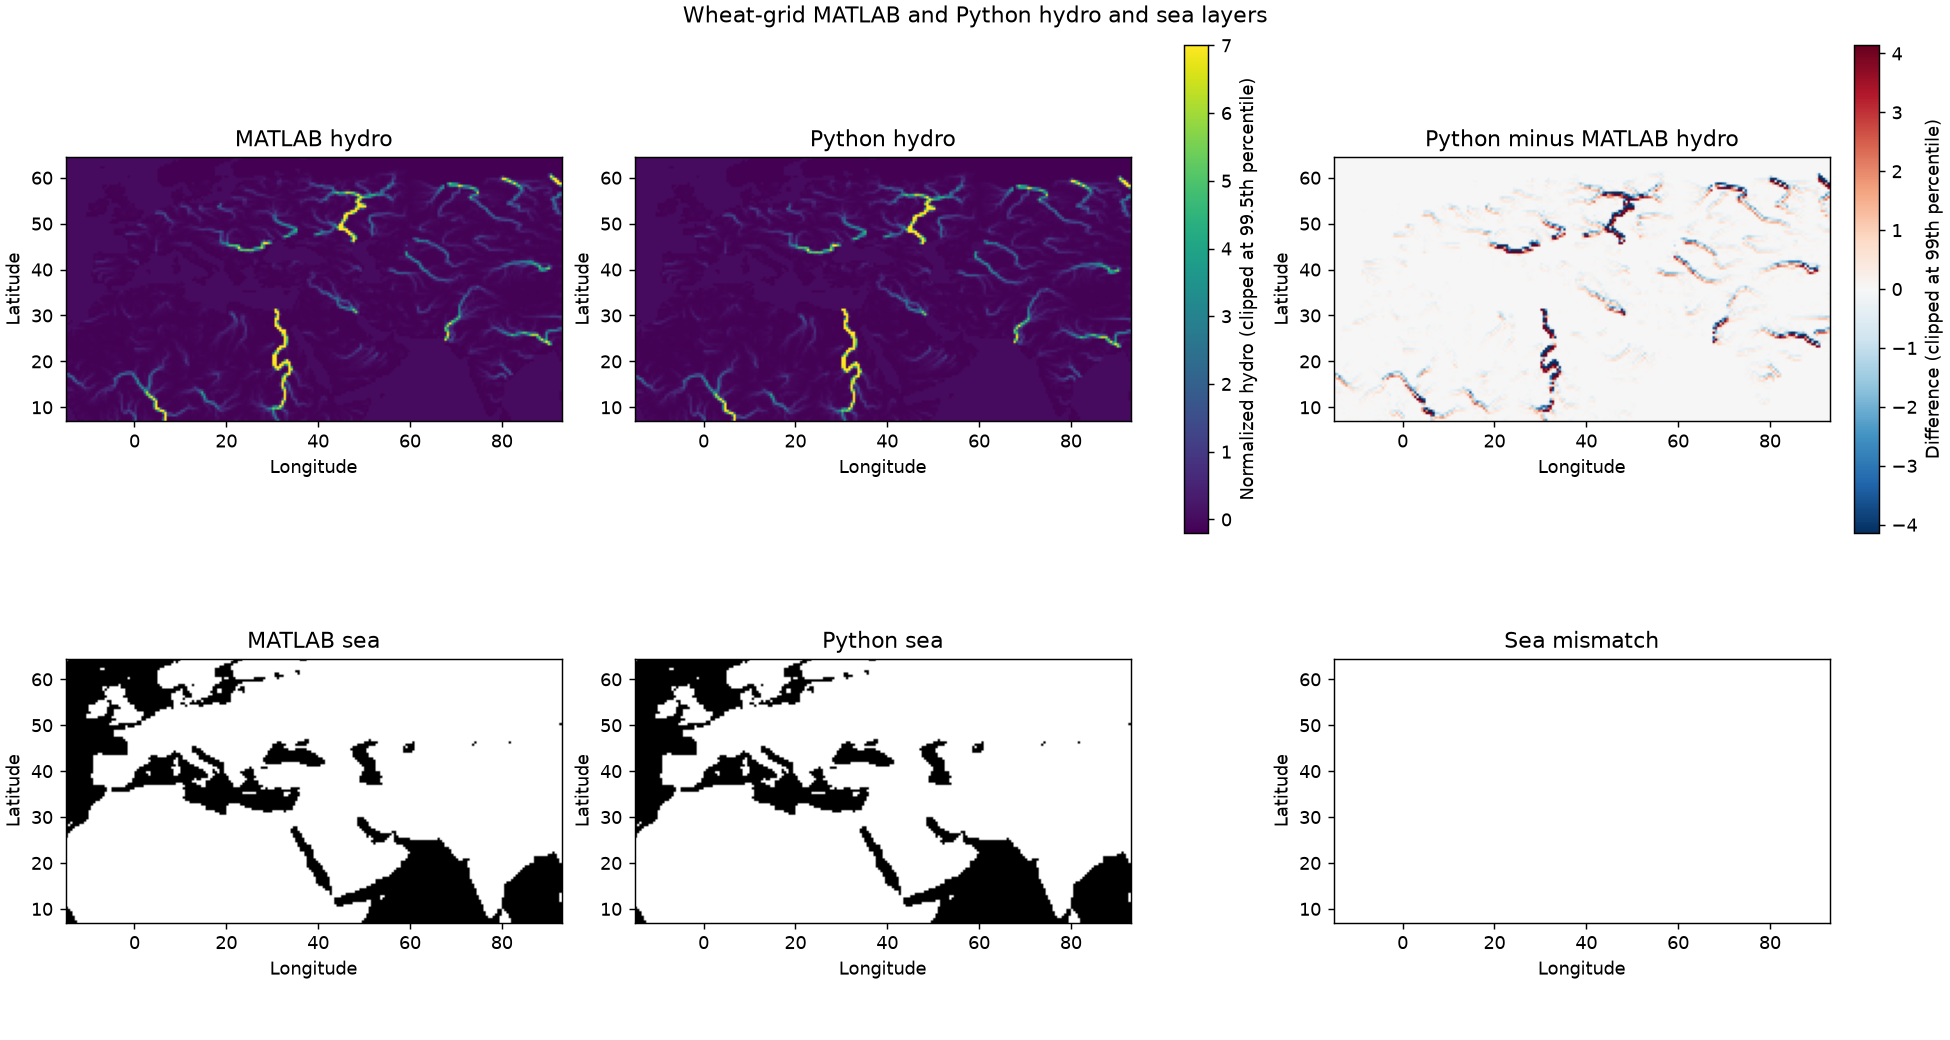

In [ ]:
# Compare MATLAB's saved parameters.X with the app's processed wheat layers.
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from diffusion_estimator import DiffusionEstimator

root = Path.cwd()
if not (root / "diffusion_estimator.py").exists():
    root = next(p for p in Path.cwd().parents if (p / "diffusion_estimator.py").exists())
fit_path = (root.parent / "bottlenecks" / "generated_data" / "sweep_grad_descent"
            / "all_wheat_av_hydro_sea_100av_2026-03-21_21-45.mat")
fit = loadmat(fit_path, simplify_cells=True,
              variable_names=["parameters", "theta_optim", "number_of_averages", "result"])
mat_hydro, mat_sea = (np.asarray(x, dtype=float) for x in fit["parameters"]["X"])
estimator = DiffusionEstimator("wheat", ["hydro", "sea"], delta=0.5, dt=40)
py_hydro = np.asarray(estimator.layer_data["hydro"], dtype=float)
py_sea = np.asarray(estimator.layer_data["sea"], dtype=float)
assert mat_hydro.shape == py_hydro.shape == mat_sea.shape == py_sea.shape

diff = py_hydro - mat_hydro
same_cell_corr = np.corrcoef(mat_hydro.ravel(), py_hydro.ravel())[0, 1]
# Latitude increases with row index; Python's features are one row south.
shifted_corr = np.corrcoef(mat_hydro[1:].ravel(), py_hydro[:-1].ravel())[0, 1]
sea_mismatches = np.count_nonzero(py_sea != mat_sea)
print(f"Grid: {mat_hydro.shape}; sea mismatches: {sea_mismatches}/{mat_sea.size}")
print(f"Hydro: MAE={np.mean(np.abs(diff)):.6f}; RMSE={np.sqrt(np.mean(diff**2)):.6f}; "
      f"max |difference|={np.max(np.abs(diff)):.6f}")
print(f"Hydro correlation: same cell={same_cell_corr:.6f}; "
      f"Python shifted north one row={shifted_corr:.6f}")
print(f"Maximum hydro cell: MATLAB={np.unravel_index(np.argmax(mat_hydro), mat_hydro.shape)}, "
      f"Python={np.unravel_index(np.argmax(py_hydro), py_hydro.shape)}")

# Confirm the source of the half-degree placement offset on the European tile.
world_file = (root.parent / "bottlenecks" / "data" / "raw" / "HydroSHEDS"
              / "ACC" / "eu_acc_30s_bil" / "eu_acc_30s.blw")
world = np.loadtxt(world_file)
global_lat = -89.75 + 0.5 * np.arange(360)
mat_top = global_lat[np.searchsorted(global_lat, world[5] - world[0] / 2)]
native_top_coarse = global_lat[np.argmin(np.abs(global_lat - world[5]))]
print(f"EU tile top: native {world[5]:.6f}°, MATLAB placement {mat_top:.2f}°, "
      f"global-resize centre {native_top_coarse:.2f}°")

extent = (estimator.longitude[0] - 0.25, estimator.longitude[-1] + 0.25,
          estimator.latitude[0] - 0.25, estimator.latitude[-1] + 0.25)
hydro_cap = np.quantile(np.r_[mat_hydro.ravel(), py_hydro.ravel()], 0.995)
diff_cap = np.quantile(np.abs(diff), 0.99)
fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
for ax, values, title in zip(axes[0, :2], (mat_hydro, py_hydro),
                             ("MATLAB hydro", "Python hydro")):
    hydro_image = ax.imshow(values, origin="lower", extent=extent, cmap="viridis",
                            vmin=-0.2, vmax=hydro_cap)
    ax.set_title(title)
fig.colorbar(hydro_image, ax=axes[0, :2].tolist(), label="Normalized hydro (99.5% clip)")
diff_image = axes[0, 2].imshow(diff, origin="lower", extent=extent, cmap="RdBu_r",
                               vmin=-diff_cap, vmax=diff_cap)
axes[0, 2].set_title("Python minus MATLAB hydro")
fig.colorbar(diff_image, ax=axes[0, 2], label="Difference (99% clip)")
for ax, values, title in zip(axes[1], (mat_sea, py_sea, py_sea != mat_sea),
                             ("MATLAB sea", "Python sea", "Sea mismatch")):
    ax.imshow(values, origin="lower", extent=extent, cmap="gray_r", vmin=0, vmax=1)
    ax.set_title(title)
for ax in axes.ravel():
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
fig.suptitle("Wheat grid: MATLAB parameters.X versus app layers")
display(fig)
plt.close(fig)


In [ ]:
# Hold Python's solver, theta, seed and repetition count fixed; swap only the layers.
from calculate_errors import calculate_mse

theta = np.atleast_1d(fit["theta_optim"]).astype(float)
n_reps = int(fit["number_of_averages"])
matlab_dataset = np.asarray(fit["parameters"]["dataset_idx"], dtype=float) - 1
assert np.array_equal(estimator.dataset[:, :2], matlab_dataset[:, :2])
def logistic(x):
    return 1 / (1 + np.exp(-x))

speed_maps = {
    "Python hydro + sea": estimator.build_speed(theta),
    "MATLAB parameters.X": logistic(theta[0] + theta[1] * mat_hydro + theta[2] * mat_sea),
}
print(f"MATLAB saved MSE: {float(fit['result']['squared_error']):,.0f} years²")
for label, speed in speed_maps.items():
    arrival, app_mse = estimator.calculate_simulation_times_and_error(
        speed, n_reps=n_reps, random_state=12, apply_w=True)
    matlab_bin_mse = calculate_mse(matlab_dataset, arrival, estimator.dt)
    print(f"{label}: Python MSE {app_mse:,.0f} years²; "
          f"with MATLAB observation bins {matlab_bin_mse:,.0f} years²")


MATLAB saved MSE: 1,591,569 years²
Python hydro + sea: Python MSE 3,683,473 years²; with MATLAB observation bins 3,683,187 years²
MATLAB parameters.X: Python MSE 1,694,240 years²; with MATLAB observation bins 1,693,798 years²
